In [5]:
import h5py

file_path = "/home/junsung/cross_modal_tactile/tactile_benchmark/data/recordings/processed/dai_dai_object_pnp/episode_0000.hdf5"

def print_structure(name, obj):
    if isinstance(obj, h5py.Dataset):
        print(f"[DATASET] {name} | shape={obj.shape} | dtype={obj.dtype}")
    else:
        print(f"[GROUP]   {name}")

with h5py.File(file_path, "r") as f:
    f.visititems(print_structure)

[DATASET] action | shape=(359, 128) | dtype=float32
[DATASET] observation.image.cam0 | shape=(359, 240, 320, 3) | dtype=uint8
[DATASET] observation.image.cam1 | shape=(359, 240, 320, 3) | dtype=uint8
[DATASET] observation.image.tac0 | shape=(359, 240, 320, 3) | dtype=uint8
[DATASET] observation.image.tac1 | shape=(359, 240, 320, 3) | dtype=uint8
[DATASET] observation.state | shape=(359, 128) | dtype=float32
[DATASET] observation.tac0 | shape=(359, 384000) | dtype=float32
[DATASET] observation.tac1 | shape=(359, 384000) | dtype=float32


raw tac0 shape: (359, 384000)
reconstructed frame shape: (240, 320, 5)


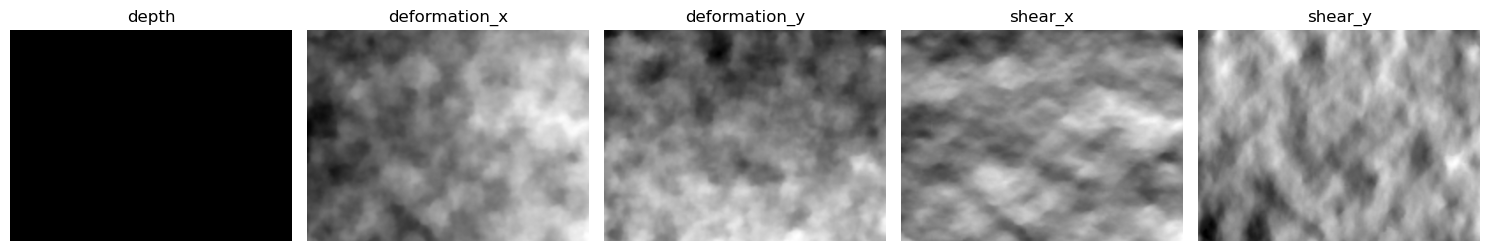

In [7]:
import h5py
import numpy as np
import matplotlib.pyplot as plt

file_path = "/home/junsung/cross_modal_tactile/tactile_benchmark/data/recordings/processed/dai_dai_object_pnp/episode_0000.hdf5"

channel_names = [
    "depth",
    "deformation_x",
    "deformation_y",
    "shear_x",
    "shear_y"
]

# 보고 싶은 time index
t = 0

H, W = 240, 320
N = H * W

with h5py.File(file_path, "r") as f:
    tac0 = f["observation.tac0"][:]   # shape: (359, 384000)

print("raw tac0 shape:", tac0.shape)

# 한 프레임 꺼내기: shape (384000,)
flat = tac0[t]

# 저장 순서:
# [depth.flatten(), deformation.flatten(), shear.flatten()]
# deformation: (H, W, 2)
# shear:       (H, W, 2)

depth = flat[:N].reshape(H, W)
deformation = flat[N:3*N].reshape(H, W, 2)
shear = flat[3*N:5*N].reshape(H, W, 2)

# 최종 5채널로 재조립
s0_correct = np.concatenate([
    depth[..., None],
    deformation,
    shear
], axis=-1)

print("reconstructed frame shape:", s0_correct.shape)

plt.figure(figsize=(15, 6))

for i in range(5):
    ch = s0_correct[:, :, i]

    plt.subplot(1, 5, i + 1)
    plt.imshow(ch, cmap="gray")
    plt.title(channel_names[i])
    plt.axis("off")

plt.tight_layout()
plt.show()

In [10]:
import h5py
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.animation import FuncAnimation
from IPython.display import HTML

file_path = "/home/junsung/cross_modal_tactile/tactile_benchmark/data/recordings/processed/dai_dai_object_pnp/episode_0000.hdf5"

channel_names = [
    "depth",
    "deformation_x",
    "deformation_y",
    "shear_x",
    "shear_y"
]

H, W = 240, 320
N = H * W

with h5py.File(file_path, "r") as f:
    tac0 = f["observation.tac0"][:]   # shape: (T, 384000)

T = tac0.shape[0]
print("tac0 shape:", tac0.shape)

# 전체 프레임을 (T, H, W, 5) 로 복원
frames = np.zeros((T, H, W, 5), dtype=np.float32)

for t in range(T):
    flat = tac0[t]

    depth = flat[:N].reshape(H, W)
    deformation = flat[N:3*N].reshape(H, W, 2)
    shear = flat[3*N:5*N].reshape(H, W, 2)

    frames[t] = np.concatenate([
        depth[..., None],
        deformation,
        shear
    ], axis=-1)

print("frames shape:", frames.shape)

# 각 채널별 고정 min/max 계산
vmins = [frames[:, :, :, i].min() for i in range(5)]
vmaxs = [frames[:, :, :, i].max() for i in range(5)]

fig, axes = plt.subplots(1, 5, figsize=(18, 4))
ims = []

for i, ax in enumerate(axes):
    im = ax.imshow(frames[0, :, :, i], cmap="gray", vmin=vmins[i], vmax=vmaxs[i], animated=True)
    ax.set_title(channel_names[i])
    ax.axis("off")
    ims.append(im)

title = fig.suptitle("frame 0")

def update(frame_idx):
    for i in range(5):
        ims[i].set_array(frames[frame_idx, :, :, i])
    title.set_text(f"frame {frame_idx}")
    return ims + [title]

anim = FuncAnimation(
    fig,
    update,
    frames=T,
    interval=50,   # ms, 작을수록 빠름
    blit=False
)

plt.close(fig)
HTML(anim.to_jshtml())
anim.save("tac0_animation.mp4", fps=20)

tac0 shape: (359, 384000)
frames shape: (359, 240, 320, 5)


Animation size has reached 21007838 bytes, exceeding the limit of 20971520.0. If you're sure you want a larger animation embedded, set the animation.embed_limit rc parameter to a larger value (in MB). This and further frames will be dropped.


In [11]:
import matplotlib.pyplot as plt

sample_path = pkl_files[80]

with open(sample_path, "rb") as f:
    sample = pickle.load(f)

img0 = sample["img0"]  # shape (480, 640, 3), uint8

plt.imshow(img0)
plt.title("img0")
plt.axis("off")
plt.show()

NameError: name 'pkl_files' is not defined